# Probability Distributions — APS / M.Tech AIML Lab Notebook

This notebook follows the same workflow as your uploaded binomial lab:
1. Define the random variable and identify the distribution.
2. State the possible values / support and the parameters.
3. Generate random observations using NumPy.
4. Count outcomes and calculate empirical probabilities (discrete) or plot an empirical density (continuous).
5. Compare empirical results with theoretical PMF/PDF.
6. Calculate theoretical and empirical mean and variance.
7. Repeat with larger sample sizes and observe convergence.

**How to use:** Run each section from top to bottom. First read the problem and answer the questions in the markdown cells; then run the code and compare your answers. The examples are illustrative, so you can change the parameters and rerun the cells.

**Important:** `np.var()` uses population variance (`ddof=0`) by default. This is the convention used for the empirical variance in this notebook, matching the uploaded lab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)  # Makes the simulation reproducible
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True

## 1. Binomial Distribution

### Problem: Number of customers who click an advertisement

An organization sends an advertisement to **20 customers**. Each customer independently clicks the advertisement with probability **0.3**.

Let \(X\) = number of customers who click.

### Questions — try before running the code
1. What is one trial? What is a success?
2. What are the values of \(n\) and \(p\)?
3. Is \(X\) discrete or continuous?
4. What are the possible values of \(X\)?
5. Which distribution is suitable, and why?
6. What is the theoretical mean and variance?

**Identification:** A fixed number of independent trials, two outcomes per trial, and constant success probability → Binomial distribution.

\[
X\\sim\\operatorname{Binomial}(n,p),\\quad
P(X=x)=\\binom{n}{x}p^x(1-p)^{n-x}
\]
\[
E[X]=np,\\qquad \\operatorname{Var}(X)=np(1-p)
\]

In [2]:
# Step 1: Define the parameters and simulate observations
n = 20
p = 0.30
sample_size = 10_000

samples_bin = np.random.binomial(n=n, p=p, size=sample_size)

print("First 20 simulated values:", samples_bin[:20])
print("Number of simulated periods:", len(samples_bin))
print("Possible values:", np.arange(0, n + 1))

First 20 simulated values: [ 5  9  7  6  4  4  3  8  6  7  2 10  8  4  4  4  5  6  6  5]
Number of simulated periods: 10000
Possible values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]


### Q&A: Understand the generated sample
- How many observations were generated? `sample_size`.
- What does a value such as 7 represent? Seven clicks out of 20 customers in one simulated period.
- Why can the output never be 21? There are only 20 trials.

In [3]:
# Step 2: Count observed values and calculate empirical PMF
x_bin = np.arange(n + 1)
counts_bin = np.array([np.sum(samples_bin == x) for x in x_bin])
empirical_pmf_bin = counts_bin / sample_size

# Step 3: Theoretical PMF
theoretical_pmf_bin = stats.binom.pmf(x_bin, n=n, p=p)

print("x | Count | Empirical P(X=x) | Theoretical P(X=x)")
for x, count, ep, tp in zip(x_bin, counts_bin, empirical_pmf_bin, theoretical_pmf_bin):
    print(f"{x:2d} | {count:5d} | {ep:.4f}            | {tp:.4f}")

x | Count | Empirical P(X=x) | Theoretical P(X=x)
 0 |    14 | 0.0014            | 0.0008
 1 |    51 | 0.0051            | 0.0068
 2 |   278 | 0.0278            | 0.0278
 3 |   770 | 0.0770            | 0.0716
 4 |  1299 | 0.1299            | 0.1304
 5 |  1829 | 0.1829            | 0.1789
 6 |  1954 | 0.1954            | 0.1916
 7 |  1605 | 0.1605            | 0.1643
 8 |  1109 | 0.1109            | 0.1144
 9 |   645 | 0.0645            | 0.0654
10 |   296 | 0.0296            | 0.0308
11 |   101 | 0.0101            | 0.0120
12 |    39 | 0.0039            | 0.0039
13 |    10 | 0.0010            | 0.0010
14 |     0 | 0.0000            | 0.0002
15 |     0 | 0.0000            | 0.0000
16 |     0 | 0.0000            | 0.0000
17 |     0 | 0.0000            | 0.0000
18 |     0 | 0.0000            | 0.0000
19 |     0 | 0.0000            | 0.0000
20 |     0 | 0.0000            | 0.0000


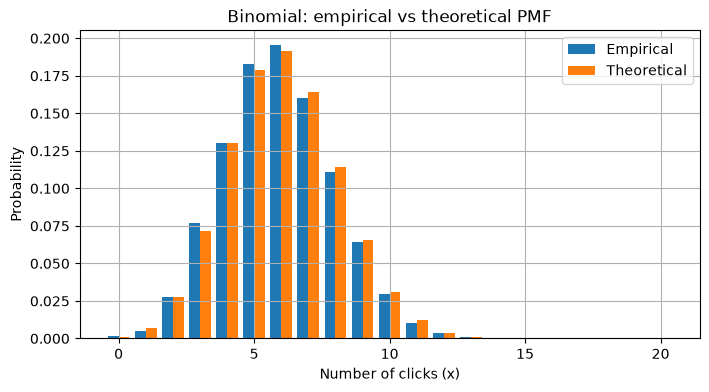

In [4]:
# Step 4: Compare empirical and theoretical PMF
width = 0.4
plt.bar(x_bin - width/2, empirical_pmf_bin, width, label="Empirical")
plt.bar(x_bin + width/2, theoretical_pmf_bin, width, label="Theoretical")
plt.xlabel("Number of clicks (x)")
plt.ylabel("Probability")
plt.title("Binomial: empirical vs theoretical PMF")
plt.legend()
plt.show()

In [5]:
# Step 5: Theoretical and empirical mean / variance
theoretical_mean_bin = n * p
theoretical_var_bin = n * p * (1 - p)

empirical_mean_bin = np.mean(samples_bin)
empirical_var_bin = np.var(samples_bin)  # ddof=0

print("Theoretical mean:", theoretical_mean_bin)
print("Empirical mean:  ", empirical_mean_bin)
print("Theoretical variance:", theoretical_var_bin)
print("Empirical variance:  ", empirical_var_bin)

Theoretical mean: 6.0
Empirical mean:   5.9563
Theoretical variance: 4.199999999999999
Empirical variance:   4.116390310000001


In [6]:
# Step 6: Observe what happens as sample size increases
sample_sizes = [10, 100, 1_000, 10_000, 100_000]
print("Size\tEmpirical mean\tEmpirical variance")
for size in sample_sizes:
    s = np.random.binomial(n=n, p=p, size=size)
    print(f"{size}\t{np.mean(s):.4f}\t\t{np.var(s):.4f}")

Size	Empirical mean	Empirical variance
10	5.7000		2.8100
100	6.0300		5.0691
1000	6.0480		4.0557
10000	6.0397		4.2639
100000	5.9954		4.1759


## 2. Hypergeometric Distribution

### Problem: Defective products selected without replacement

A box contains **20 products**, of which **6 are defective** and **14 are good**. An inspector randomly selects **5 products without replacement**.

Let \(X\) = number of defective products in the sample.

### Questions
1. What is the population size \(N\)?
2. How many success items \(K\) are in the population?
3. What is the sample size \(n\)?
4. Why is this not a binomial experiment?
5. Is \(X\) discrete or continuous? What is its support?
6. Find its theoretical mean and variance.

**Identification:** Fixed-size sampling **without replacement** from a finite population → Hypergeometric distribution.

\[
X\\sim\\operatorname{Hypergeometric}(N,K,n)
\]
\[
P(X=x)=\\frac{\\binom Kx\\binom{N-K}{n-x}}{\\binom Nn}
\]
\[
E[X]=n\\frac KN,\\quad
\\operatorname{Var}(X)=n\\frac KN\\left(1-\\frac KN\\right)\\frac{N-n}{N-1}
\]

The possible values are from \(\max(0,n-(N-K))\) to \(\min(n,K)\).

In [7]:
# Step 1: Define parameters and simulate
N = 20       # Total population
K = 6        # Defective items (successes)
n_h = 5      # Items selected without replacement
sample_size_h = 10_000

samples_hyp = np.random.hypergeometric(ngood=K, nbad=N-K, nsample=n_h, size=sample_size_h)

low_h = max(0, n_h - (N-K))
high_h = min(n_h, K)
x_h = np.arange(low_h, high_h + 1)

print("First 20 simulated values:", samples_hyp[:20])
print("Possible values:", x_h)

First 20 simulated values: [2 1 1 3 1 2 2 2 1 1 3 1 1 2 1 3 0 3 1 1]
Possible values: [0 1 2 3 4 5]


x | Count | Empirical PMF | Theoretical PMF
 0 |  1272 | 0.1272        | 0.1291
 1 |  3868 | 0.3868        | 0.3874
 2 |  3495 | 0.3495        | 0.3522
 3 |  1226 | 0.1226        | 0.1174
 4 |   136 | 0.0136        | 0.0135
 5 |     3 | 0.0003        | 0.0004


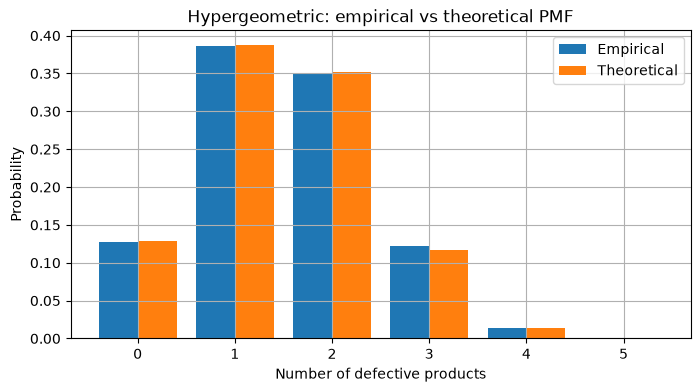

In [8]:
# Step 2: Empirical and theoretical PMF
counts_h = np.array([np.sum(samples_hyp == x) for x in x_h])
empirical_pmf_h = counts_h / sample_size_h
theoretical_pmf_h = stats.hypergeom.pmf(x_h, M=N, n=K, N=n_h)

print("x | Count | Empirical PMF | Theoretical PMF")
for x, c, ep, tp in zip(x_h, counts_h, empirical_pmf_h, theoretical_pmf_h):
    print(f"{x:2d} | {c:5d} | {ep:.4f}        | {tp:.4f}")

plt.bar(x_h - 0.2, empirical_pmf_h, 0.4, label="Empirical")
plt.bar(x_h + 0.2, theoretical_pmf_h, 0.4, label="Theoretical")
plt.xlabel("Number of defective products")
plt.ylabel("Probability")
plt.title("Hypergeometric: empirical vs theoretical PMF")
plt.legend()
plt.show()

In [9]:
# Step 3: Theoretical and empirical mean / variance
theoretical_mean_h = n_h * (K / N)
theoretical_var_h = n_h * (K/N) * (1-K/N) * ((N-n_h)/(N-1))

empirical_mean_h = np.mean(samples_hyp)
empirical_var_h = np.var(samples_hyp)

print("Theoretical mean:", theoretical_mean_h)
print("Empirical mean:  ", empirical_mean_h)
print("Theoretical variance:", theoretical_var_h)
print("Empirical variance:  ", empirical_var_h)

Theoretical mean: 1.5
Empirical mean:   1.5095
Theoretical variance: 0.8289473684210525
Empirical variance:   0.8347097500000001


## 3. Geometric Distribution

### Problem: Number of calls until the first successful response

A support agent calls customers. Each call independently results in a response with probability **0.25**. Calls continue until the first response.

Let \(X\) = number of calls made until the first successful response.

### Questions
1. What is a success?
2. What is the probability of success \(p\)?
3. Can \(X=0\)? Why or why not?
4. What are the possible values of \(X\)?
5. Why is the geometric distribution suitable?
6. Find the theoretical mean and variance.

**NumPy convention used here:** `np.random.geometric(p)` counts the trial of the first success, so support is \(1,2,3,\\ldots\).

\[
P(X=x)=(1-p)^{x-1}p,\\quad
E[X]=\\frac1p,\\quad
\\operatorname{Var}(X)=\\frac{1-p}{p^2}
\]

Note: Some textbooks define the variable as the number of failures before the first success. That version starts at 0. Do not mix the two conventions.

In [10]:
# Step 1: Simulate number of trials until first success
p_g = 0.25
sample_size_g = 10_000

samples_geo = np.random.geometric(p=p_g, size=sample_size_g)
print("First 20 simulated values:", samples_geo[:20])
print("Minimum observed value:", samples_geo.min())

First 20 simulated values: [1 6 4 7 2 3 5 9 1 9 1 2 1 8 2 4 3 8 1 2]
Minimum observed value: 1


x | Count | Empirical PMF | Theoretical PMF
 1 |  2431 | 0.2431        | 0.2500
 2 |  1955 | 0.1955        | 0.1875
 3 |  1377 | 0.1377        | 0.1406
 4 |  1097 | 0.1097        | 0.1055
 5 |   820 | 0.0820        | 0.0791
 6 |   559 | 0.0559        | 0.0593
 7 |   445 | 0.0445        | 0.0445
 8 |   341 | 0.0341        | 0.0334
 9 |   241 | 0.0241        | 0.0250
10 |   173 | 0.0173        | 0.0188
11 |   135 | 0.0135        | 0.0141
12 |   106 | 0.0106        | 0.0106
13 |    89 | 0.0089        | 0.0079
14 |    61 | 0.0061        | 0.0059
15 |    42 | 0.0042        | 0.0045


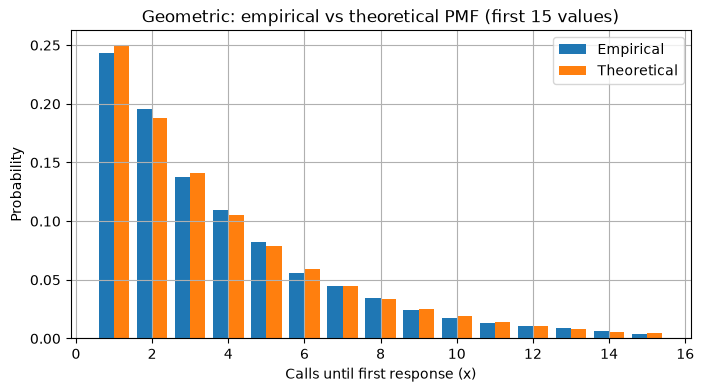

In [11]:
# Step 2: Empirical PMF and theoretical PMF
# Limit the display to values 1 through 15; the remaining tail is not shown.
x_g = np.arange(1, 16)
counts_g = np.array([np.sum(samples_geo == x) for x in x_g])
empirical_pmf_g = counts_g / sample_size_g
theoretical_pmf_g = stats.geom.pmf(x_g, p=p_g)

print("x | Count | Empirical PMF | Theoretical PMF")
for x, c, ep, tp in zip(x_g, counts_g, empirical_pmf_g, theoretical_pmf_g):
    print(f"{x:2d} | {c:5d} | {ep:.4f}        | {tp:.4f}")

plt.bar(x_g - 0.2, empirical_pmf_g, 0.4, label="Empirical")
plt.bar(x_g + 0.2, theoretical_pmf_g, 0.4, label="Theoretical")
plt.xlabel("Calls until first response (x)")
plt.ylabel("Probability")
plt.title("Geometric: empirical vs theoretical PMF (first 15 values)")
plt.legend()
plt.show()

In [12]:
# Step 3: Theoretical and empirical mean / variance
theoretical_mean_g = 1 / p_g
theoretical_var_g = (1 - p_g) / (p_g ** 2)

empirical_mean_g = np.mean(samples_geo)
empirical_var_g = np.var(samples_geo)

print("Theoretical mean:", theoretical_mean_g)
print("Empirical mean:  ", empirical_mean_g)
print("Theoretical variance:", theoretical_var_g)
print("Empirical variance:  ", empirical_var_g)

Theoretical mean: 4.0
Empirical mean:   3.9919
Theoretical variance: 12.0
Empirical variance:   11.95043439


## 4. Normal Distribution

### Problem: Distribution of examination scores

Suppose examination scores are approximately normally distributed with mean **70** and standard deviation **10**.

Let \(X\) = score of a randomly selected student.

### Questions
1. Is \(X\) discrete or continuous?
2. What are the mean \(\mu\) and standard deviation \(\sigma\)?
3. What is the variance?
4. Why do we use a PDF rather than a PMF?
5. What proportion of scores is expected to be below 60?
6. What are the theoretical mean and variance?

**Identification:** A continuous, symmetric, bell-shaped variable described by a mean and standard deviation → Normal distribution.

\[
X\\sim N(\\mu,\\sigma^2),\\quad E[X]=\\mu,\\quad \\operatorname{Var}(X)=\\sigma^2
\]

For a continuous variable, \(P(X=x)=0\) at any exact point. Probabilities are areas over intervals, such as \(P(60\\le X\\le80)\).

In [13]:
# Step 1: Define parameters and simulate
mu = 70
sigma = 10
sample_size_n = 10_000

samples_norm = np.random.normal(loc=mu, scale=sigma, size=sample_size_n)
print("First 20 simulated scores:", np.round(samples_norm[:20], 2))
print("Observed sample minimum:", samples_norm.min())
print("Observed sample maximum:", samples_norm.max())

First 20 simulated scores: [77.46 71.19 73.3  69.49 86.34 71.8  72.72 67.13 55.92 85.98 66.11 75.8
 82.02 68.58 85.13 63.71 50.48 62.38 73.41 70.9 ]
Observed sample minimum: 32.05362560621412
Observed sample maximum: 106.6522945865144


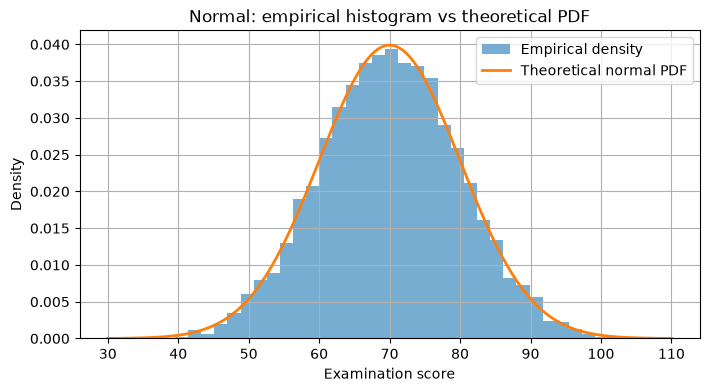

P(X < 60): 0.15865525393145707
P(60 <= X <= 80): 0.6826894921370859


In [14]:
# Step 2: Plot empirical density and theoretical PDF
x_norm = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
theoretical_pdf_norm = stats.norm.pdf(x_norm, loc=mu, scale=sigma)

plt.hist(samples_norm, bins=40, density=True, alpha=0.6, label="Empirical density")
plt.plot(x_norm, theoretical_pdf_norm, linewidth=2, label="Theoretical normal PDF")
plt.xlabel("Examination score")
plt.ylabel("Density")
plt.title("Normal: empirical histogram vs theoretical PDF")
plt.legend()
plt.show()

# Example interval probabilities using the CDF
print("P(X < 60):", stats.norm.cdf(60, loc=mu, scale=sigma))
print("P(60 <= X <= 80):", stats.norm.cdf(80, loc=mu, scale=sigma) - stats.norm.cdf(60, loc=mu, scale=sigma))

In [15]:
# Step 3: Theoretical and empirical mean / variance
theoretical_mean_norm = mu
theoretical_var_norm = sigma ** 2

empirical_mean_norm = np.mean(samples_norm)
empirical_var_norm = np.var(samples_norm)

print("Theoretical mean:", theoretical_mean_norm)
print("Empirical mean:  ", empirical_mean_norm)
print("Theoretical variance:", theoretical_var_norm)
print("Empirical variance:  ", empirical_var_norm)

Theoretical mean: 70
Empirical mean:   70.05388279800572
Theoretical variance: 100
Empirical variance:   98.63250759516494


## 5. Uniform Distribution

### Problem: Waiting time for a shuttle

A shuttle arrives at a random time between **0 and 20 minutes** after a passenger arrives. Assume every time in this interval is equally likely.

Let \(X\) = passenger's waiting time in minutes.

### Questions
1. Is \(X\) discrete or continuous?
2. What are the lower limit \(a\) and upper limit \(b\)?
3. What is the PDF inside the interval?
4. What is the probability of waiting between 5 and 10 minutes?
5. What are the theoretical mean and variance?

**Identification:** A continuous variable with constant density between two limits → Continuous Uniform distribution.

\[
X\\sim U(a,b),\\quad f(x)=\\frac{1}{b-a},\\ a\\le x\\le b
\]
\[
E[X]=\\frac{a+b}{2},\\qquad
\\operatorname{Var}(X)=\\frac{(b-a)^2}{12}
\]

For continuous distributions, compare the theoretical PDF curve with a histogram using `density=True`; do not compare point probabilities as if it were a discrete PMF.

In [16]:
# Step 1: Define parameters and simulate
a = 0
b = 20
sample_size_u = 10_000

samples_unif = np.random.uniform(low=a, high=b, size=sample_size_u)
print("First 20 waiting times:", np.round(samples_unif[:20], 2))
print("Observed minimum:", samples_unif.min())
print("Observed maximum:", samples_unif.max())

First 20 waiting times: [13.16  8.65  7.87 14.18  8.58  9.69  1.58  9.95 14.11  1.82  0.78 14.52
  2.08  5.9  13.05 17.01  7.44 14.41 12.2  11.95]
Observed minimum: 0.0046964842779018134
Observed maximum: 19.99955546287197


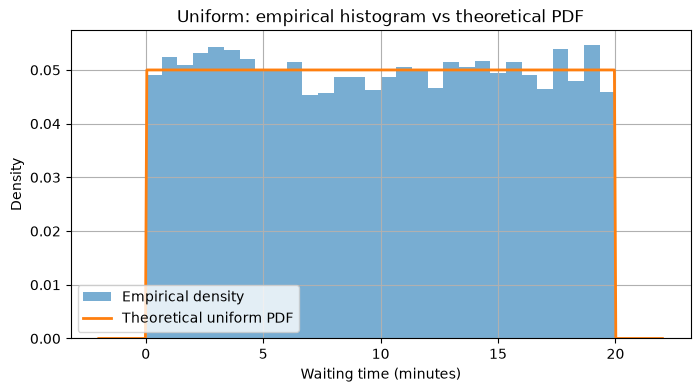

P(5 <= X <= 10): 0.25


In [17]:
# Step 2: Plot empirical density and theoretical PDF
x_unif = np.linspace(a - 2, b + 2, 400)
theoretical_pdf_unif = stats.uniform.pdf(x_unif, loc=a, scale=b-a)

plt.hist(samples_unif, bins=30, density=True, alpha=0.6, label="Empirical density")
plt.plot(x_unif, theoretical_pdf_unif, linewidth=2, label="Theoretical uniform PDF")
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Density")
plt.title("Uniform: empirical histogram vs theoretical PDF")
plt.legend()
plt.show()

# Example interval probability
prob_5_to_10 = stats.uniform.cdf(10, loc=a, scale=b-a) - stats.uniform.cdf(5, loc=a, scale=b-a)
print("P(5 <= X <= 10):", prob_5_to_10)

In [18]:
# Step 3: Theoretical and empirical mean / variance
theoretical_mean_u = (a + b) / 2
theoretical_var_u = ((b - a) ** 2) / 12

empirical_mean_u = np.mean(samples_unif)
empirical_var_u = np.var(samples_unif)

print("Theoretical mean:", theoretical_mean_u)
print("Empirical mean:  ", empirical_mean_u)
print("Theoretical variance:", theoretical_var_u)
print("Empirical variance:  ", empirical_var_u)

Theoretical mean: 10.0
Empirical mean:   9.940035593144044
Theoretical variance: 33.333333333333336
Empirical variance:   33.72998876098824


## 6. Quick comparison / exam revision sheet

| Distribution | Type | Parameters | Theoretical mean | Theoretical variance |
|---|---|---|---|---|
| Binomial | Discrete | \(n,p\) | \(np\) | \(np(1-p)\) |
| Hypergeometric | Discrete | \(N,K,n\) | \(nK/N\) | \(n(K/N)(1-K/N)((N-n)/(N-1))\) |
| Geometric (trials to first success) | Discrete | \(p\) | \(1/p\) | \((1-p)/p^2\) |
| Normal | Continuous | \(\mu,\sigma\) | \(\mu\) | \(\sigma^2\) |
| Uniform | Continuous | \(a,b\) | \((a+b)/2\) | \((b-a)^2/12\) |

### How to identify the distribution in a question
- **Binomial:** fixed number of independent yes/no trials; count successes.
- **Hypergeometric:** select a sample from a finite population without replacement; count successes.
- **Geometric:** count trials until the first success.
- **Normal:** continuous measurement around a mean; bell-shaped model.
- **Uniform:** continuous measurement where every value in a stated interval has equal density.

### Important coding patterns
- Discrete simulation: `np.random.binomial`, `np.random.hypergeometric`, `np.random.geometric`.
- Continuous simulation: `np.random.normal`, `np.random.uniform`.
- Discrete theoretical probabilities: `scipy.stats.<distribution>.pmf(...)`.
- Continuous theoretical density: `scipy.stats.<distribution>.pdf(...)`.
- Interval probability for continuous variables: use CDF differences.
- Empirical mean: `np.mean(samples)`.
- Empirical population variance: `np.var(samples)`.

### Self-test — answer without looking above
1. 12 bulbs are tested; each independently has probability 0.02 of being defective. What distribution models the number defective?
2. 4 cards are drawn from a deck without replacement. What distribution models the number of aces?
3. A player keeps attempting a shot until the first successful shot. What distribution models the number of attempts?
4. Heights are modeled as a bell-shaped continuous variable. Which distribution is commonly used?
5. A random number is selected uniformly between 3 and 9. What are its theoretical mean and variance?
6. Why does an empirical mean or variance not exactly equal its theoretical value for a finite simulation?
7. Why is `density=True` used for continuous histograms?
8. For a geometric distribution in NumPy, does the returned value include the successful trial?

### Answers
1. Binomial, if trials are independent and the probability is constant.
2. Hypergeometric.
3. Geometric.
4. Normal.
5. Mean = 6; variance = 3.
6. Random sampling variation; the estimates tend to stabilize as sample size grows.
7. To scale the histogram as a density so it can be compared with a PDF.
8. Yes. NumPy counts the successful trial, so values begin at 1.

---
**Exam reminder:** In a continuous distribution, the PDF height is not the probability at a point. The probability over an interval is the area under the PDF, calculated with a CDF difference.